# Custom external background

**Caveat: If the background source has significant output in the IR or UV, such as a star, vibrational or electronic transitions might be excited and induce fluorescence (see e.g. [Thi et al. 2013](http://dx.doi.org/10.1051/0004-6361/201219210) or [Matrà et al. 2018](https://doi.org/10.3847/1538-4357/aaa42a)). In this (over)simplified example, we only consider rotational levels of the vibrational and electronic ground states of CO, but proper modelling would need to take fluorescence into account by including vibrational and electronic transitions in the LAMDA-formatted datafile.**

`pythonradex` allows the user to define a custom external background. For example, let us assume there is a star with an effective temperature of 5000 K at a distance of 1 au from a slab of CO gas.

In [1]:
from pythonradex import radiative_transfer, helpers
from scipy import constants
import numpy as np
import matplotlib.pyplot as plt

In [2]:
datafilepath = "./co.dat"
geometry = "static slab"
line_profile_type = "rectangular"
width_v = 1 * constants.kilo
source = radiative_transfer.Source(
    datafilepath=datafilepath,
    geometry=geometry,
    line_profile_type=line_profile_type,
    width_v=width_v,
    use_datafile_frequencies=True,
)

Define the custom external background (CMB plus stellar contribution). The background is defined in the form of a standard python function, taking frequency as the only argument. 

In [3]:
CMB = helpers.generate_CMB_background(z=0)
T_star = 5000
distance = 1*constants.au
R_star = 695700*constants.kilo #same as the Sun
Omega_star = R_star**2 * np.pi / distance**2 #solid angle of the star

def averaged_stellar_field(nu):
    #for simplicity, model the stellar field as a blackbody,
    #averaged over all directions (4*pi)
    return helpers.B_nu(nu=nu,T=T_star)*Omega_star/(4*np.pi)

def external_background(nu):
    return CMB(nu) + averaged_stellar_field(nu)

Above, we simplified the problem by averaging the stellar radiation over the whole sky.

Let us plot to two background contributions:

(1e-25, 1e-12)

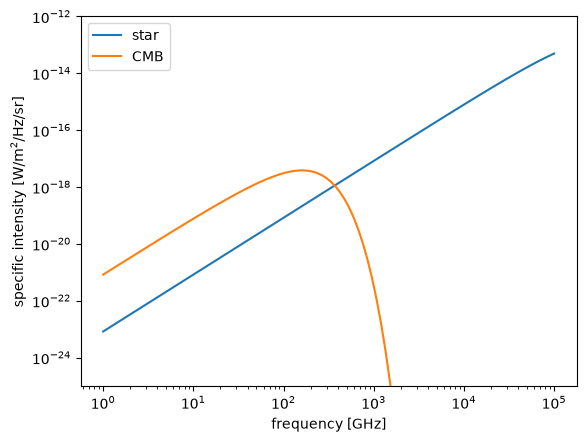

In [4]:
nu = np.logspace(0,5,100)*constants.giga
fig,ax = plt.subplots()
ax.plot(nu/constants.giga,averaged_stellar_field(nu),label="star")
ax.plot(nu/constants.giga,CMB(nu),label="CMB")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("frequency [GHz]")
ax.set_ylabel("specific intensity [W/m$^2$/Hz/sr]")
ax.legend(loc="best")
ax.set_ylim(ymin=1e-25,ymax=1e-12)

We see that for low frequencies, the CMB dominates. Beyond about 400 GHz, the stellar contribution starts to dominate.

Now calculate the CO model. We assume very low density, to emphasize the excitation contribution from the radiation fields.

In [5]:
N = 1e16 / constants.centi**2
Tkin = 20  # kinetic temperature in [K]
# collider densities in m-3:
collider_densities = {
    "para-H2": 1 / constants.centi**3,
    "ortho-H2": 1 / constants.centi**3,
}
# no dust in this example:
T_dust = tau_dust = 0
source.update_parameters(
    N=N,
    Tkin=Tkin,
    collider_densities=collider_densities,
    ext_background=external_background,
    T_dust=T_dust,
    tau_dust=tau_dust,
)

source.solve_radiative_transfer()

Text(0, 0.5, 'excitation temperature [K]')

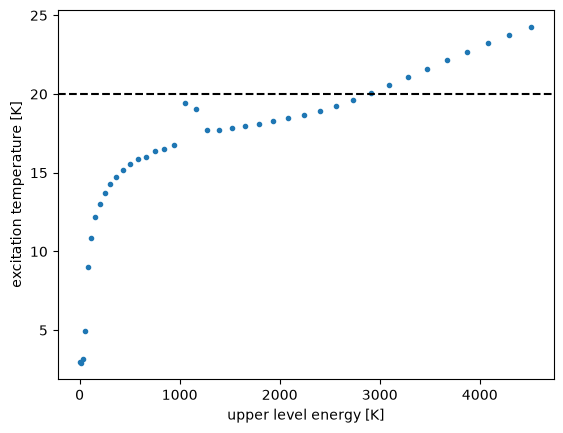

In [6]:
E_up = [trans.up.E/constants.k for trans in source.emitting_molecule.rad_transitions]

fig,ax = plt.subplots()
ax.plot(E_up,source.Tex,marker=".",linestyle="None",label="star + CMB")
ax.axhline(Tkin,color="black",linestyle="dashed",label="kinetic temperature")
ax.set_xlabel("upper level energy [K]")
ax.set_ylabel("excitation temperature [K]")

Now do the same calculation without the stellar background:

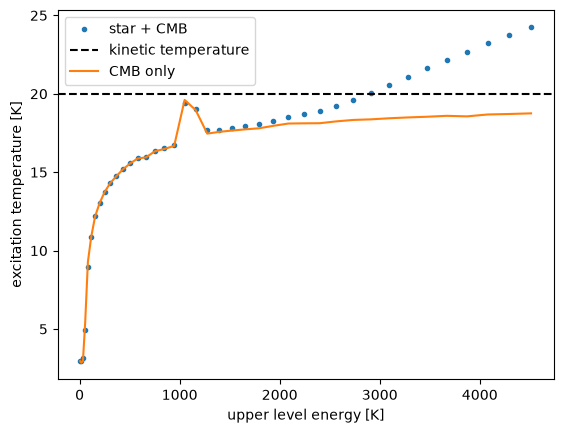

In [7]:
source.update_parameters(ext_background=CMB)
source.solve_radiative_transfer()
ax.plot(E_up,source.Tex,label="CMB only")
ax.legend(loc="best")
display(fig)

The stellar background only affects transitions from higher energy levels. Indeed, as seen above, at low energies, the stellar field is negligible compared to the CMB. **Again, proper modelling should also take fluorescence into account.**